# The projection lenses in metres, from one recording on two cameras

`at_the_microscope/record_two_cameras.py` records CLA1 and CLA2 kicks at six normal rows, then at MAG 8000 and
DIFF 40 cm with only PL1 turned down in steps, on the screen camera and on the Merlin below it, and two rulers (gold
rings and a grating image). No lens is ever weak except PL1 at those steps. This notebook fits a TemGym column to that recording:

    specimen -> objective -> IL1 -> IL2 -> IL3 -> PL1 -> screen camera -> (straight flight) -> Merlin

Every lens is a TemGym `ElectromagneticLens`. **Nothing about the column is held**: where each lens is, how strong it
is, how far apart the cameras are and how big a CLA1 and a CLA2 unit are all come out of the recording. What is put
in: the pixel size of each camera, the gold lattice spacing, the grating's lines per millimetre, and the high tension.

The fit takes about a minute. An older recording made with the weak-lens recipe is fitted the same way.

In [1]:
import csv, json, os, sys, time
from pathlib import Path

import jax
import jax.numpy as jnp
import numpy as np
from jax.flatten_util import ravel_pytree
from scipy.optimize import least_squares

jax.config.update("jax_enable_x64", True)
from temgym_core.components import ElectromagneticLens, Plane, Scanner
from temgym_core.constants import energy2wavelength
from temgym_core.run import column_matrix

RECORDING = sorted(Path("at_the_microscope/output/two_cameras").glob("*/table.csv"))[-1].parent
LENSES = ["IL1", "IL2", "IL3", "PL1"]
VOLTAGE = 200e3
V_STAR = VOLTAGE * (1 + VOLTAGE / (2 * 510998.95))
table = list(csv.DictReader(open(RECORDING / "table.csv")))
console = json.loads((RECORDING / "console.json").read_text())
about = console.get("about this recording", {})
SIMULATED = bool(about.get("simulated"))                     # the virtual NEOARM: its hidden truth can be shown next to the fit
CAMERAS = about.get("cameras", ["screenCamera", "merlin"])   # the upper camera first

# ---- what is put in ----
PIXEL = np.array([110e-6, 55e-6])                            # m per pixel: the screen camera at binning 4, the Merlin
RING_ANGLE = float(energy2wavelength(VOLTAGE)) / (0.40782e-9 / np.sqrt(3))     # the gold 111 ring: wavelength / spacing
PITCH = 1e-3 / 2160                                          # a 2160 lines per mm cross-grating

print(RECORDING, "(the virtual NEOARM)" if SIMULATED else "")
print(len(table), "frames;", jax.devices())

at_the_microscope/output/two_cameras/2026-11-16_132434 (the virtual NEOARM)
186 frames; [CudaDevice(id=0)]


## 1. What was recorded

A kick is the deflector + and - along its x, then + and - along its y. Half the difference of the two beam centres,
divided by the kick, is the response: how far one DAC unit displaces the beam on that camera (px per unit, x + iy).
Where the beam started cancels, so centring the beam does not disturb a kick.

In [2]:
def centre(row):
    return complex(float(row["beam_x_px"]), float(row["beam_y_px"])) if row["beam_usable"] == "True" else np.nan


kicks, i = [], 0
pattern = [("x", "1"), ("x", "-1"), ("y", "1"), ("y", "-1")]
while i < len(table):
    four = table[i:i + 4]
    if table[i]["role"] == "deflected" and [(r["direction"], r["sign"]) for r in four] == pattern:
        first, kick = four[0], float(four[0]["kick"])
        kicks.append(dict(stage=first["lens"] if first["stage"] == "ladder" else first["stage"], setting=first["setting"],
                          camera=CAMERAS.index(first["camera"]), deflector=first["deflector"], kick=kick,
                          lenses=[float(first[n]) for n in LENSES], cl3=float(first["CL3"]),
                          along_x=(centre(four[0]) - centre(four[1])) / (2 * kick),
                          along_y=(centre(four[2]) - centre(four[3])) / (2 * kick)))
        i += 4
    else:
        i += 1
usable = [k for k in kicks if np.isfinite(abs(k["along_x"])) and np.isfinite(abs(k["along_y"]))]
print(len(kicks), "kicks;", len(kicks) - len(usable), "left out (a frame where the beam was not usable)")
kicks = usable

settings = list(dict.fromkeys(k["setting"] for k in kicks))                # in the order recorded
rulers = [r for r in table if r["role"] in ("gold rings", "grating")
          and np.isfinite(float(r.get("ring_radius_px") or r.get("grating_pitch_px") or "nan"))]
DACS = np.array([next(k["lenses"] for k in kicks if k["setting"] == name) for name in settings]
                + [[float(r[n]) for n in LENSES] for r in rulers])
KICKS = dict(setting=np.array([settings.index(k["setting"]) for k in kicks]), camera=np.array([k["camera"] for k in kicks]),
             is_tilt=np.array([k["deflector"] == "CLA2" for k in kicks]), kick=np.array([k["kick"] for k in kicks]),
             stage=np.array([k["stage"] for k in kicks]))
RULERS = dict(setting=np.arange(len(settings), len(DACS)), camera=np.array([CAMERAS.index(r["camera"]) for r in rulers], int),
              is_gold=np.array([r["role"] == "gold rings" for r in rulers], bool))
data = dict(along_x=np.array([k["along_x"] for k in kicks]), along_y=np.array([k["along_y"] for k in kicks]),
            sizes=np.array([float(r["ring_radius_px"] if r["role"] == "gold rings" else r["grating_pitch_px"]) for r in rulers]))

print(f"\n{'setting':12s} {'IL1, IL2, IL3, PL1':30s} " + "   ".join(f"{name + ': moved by CLA1, CLA2 (px)':>36s}" for name in CAMERAS))
for index, name in enumerate(settings):
    cells_ = []
    for camera in (0, 1):
        moved = {k["deflector"]: max(abs(k["along_x"]), abs(k["along_y"])) * k["kick"] for k in kicks
                 if k["setting"] == name and k["camera"] == camera}
        cells_.append(f"{moved['CLA1']:27.1f} {moved['CLA2']:8.1f}" if len(moved) == 2 else f"{'-':>36s}")
    stage = next(k["stage"] for k in kicks if k["setting"] == name)
    print(f"{name:12s} {str([int(v) for v in DACS[index]]):30s} " + "   ".join(cells_) + ("   (kept back)" if stage == "kept" else ""))
print("\nrulers:", "; ".join(f"{r['role']} at {r['setting']} on the {r['camera']}: {size:.2f} px" for r, size in zip(rulers, data["sizes"])))
HAVE_RULERS = bool(RULERS["is_gold"].any() and (~RULERS["is_gold"]).any())
if not HAVE_RULERS:
    print("\nNo gold rings or no grating image in this recording: lengths below are NOT in real metres.")

40 kicks; 0 left out (a frame where the beam was not usable)

setting      IL1, IL2, IL3, PL1             screenCamera: moved by CLA1, CLA2 (px)       merlin: moved by CLA1, CLA2 (px)
MAG 40000    [30603, 35732, 34591, 64000]                          59.9      0.1                                      -
DIFF 40      [27385, 31741, 38330, 64000]                           1.5     60.0                           6.7     59.8
MAG 8000     [34806, 32204, 28523, 64000]                          60.0      0.1                          59.9      0.2
DIFF 15      [32095, 29550, 34210, 64000]                           1.5     32.0                                      -
MAG 200000   [28731, 46523, 45167, 64000]                          59.7      0.4                                      -
DIFF 100     [24518, 36632, 41956, 64000]                           2.1     59.9                                      -
MAG 8000, PL1 40000 [34806, 32204, 28523, 40000]                          60.0      0.7         

## 2. How well a displacement repeats

The unit every misfit is counted in. It was measured on this camera by `fit_predictor.ipynb` (the same lens values
reached again and again); a ring radius or a grating period is taken as good to 0.1 px. If the fit below ends with
misfits larger than this, the error bars are widened to match.

In [3]:
predictor = Path("results/predictor/projection_model.json")
SCATTER_PX = float(json.loads(predictor.read_text()).get("repeat_scatter_px", 0.02)) if predictor.exists() else 0.02
RULER_SCATTER_PX = 0.1
print(f"a displacement repeats to {SCATTER_PX:.4f} px; a ruler is taken as good to {RULER_SCATTER_PX} px")

a displacement repeats to 0.0219 px; a ruler is taken as good to 0.1 px


## 3. The model, and the fit from many starts

A ray that leaves the specimen at position x with angle theta reaches the screen camera at A x + B theta, travelling
with slope C x + D theta. The Merlin is a straight flight s further on, so there it is at (A + s C) x + (B + s D) theta.
A CLA1 kick changes x and a CLA2 kick changes theta. A, B, C and D come from TemGym's `column_matrix` of the column.

**The fit starts from many random columns.** Each start puts the four lenses at random places in a column of random
length, with random strengths and a random distance between the cameras, and then fits everything at once: all the
kicks (not the kept-back rows) and the rulers. Most starts end somewhere wrong, with misfits thousands of times the
scatter. The ones that find the answer all end at the same place, with misfits at the scatter. The best is kept, and
the cell says how many starts agree with it: if only one does, run more starts.

**Held at the end: nothing.**


In [4]:
def column(numbers, dac):
    "TemGym components from the specimen to the screen camera, for IL1, IL2, IL3, PL1 at these DAC values."
    z = jnp.cumsum(jnp.exp(numbers["log_gaps"]))        # objective, IL1, IL2, IL3, PL1, screen camera
    objective = ElectromagneticLens(z=z[0], turns=1.0, current=1.0, Gc=jnp.exp(numbers["log_objective_Gc"]))
    lenses = [ElectromagneticLens(z=z[i + 1], turns=numbers["ampere_turns_per_unit"][i], current=dac[i],
                                  Gc=jnp.exp(numbers["log_Gc"][i]), Tc=jnp.exp(numbers["log_Tc"][i])) for i in range(4)]
    return [objective, *lenses, Plane(z=z[5])]


def a_b_c_d(numbers, dac):
    "Position (A, B) and slope (C, D) at the screen camera per unit position and angle at the specimen (complex)."
    m = column_matrix(column(numbers, dac), voltage=VOLTAGE)
    return m[0, 0] + 1j * m[1, 0], m[0, 2] + 1j * m[1, 2], m[2, 0] + 1j * m[3, 0], m[2, 2] + 1j * m[3, 2]


def axes(deflector):
    "A deflector's x and y axes at the specimen (complex), per DAC unit."
    x_axis = jnp.exp(deflector["log_size"] + 1j * deflector["x_angle"])
    return x_axis, x_axis * (deflector["y_axis"][0] + 1j * deflector["y_axis"][1])


def on_camera(numbers, setting, camera):
    "A and B at a camera, in pixels and in the camera's own orientation, for each (setting, camera) asked for."
    a, b, c, d = jax.vmap(a_b_c_d, in_axes=(None, 0))(numbers["lenses"], jnp.asarray(DACS))
    flight = jnp.where(camera == 1, jnp.exp(numbers["log_separation"]), 0.0)
    turned = jnp.exp(1j * (numbers["camera_rotation"] + jnp.where(camera == 1, numbers["merlin_rotation"], 0.0)))
    scale = turned / jnp.asarray(PIXEL)[camera]
    return scale * (a[setting] + flight * c[setting]), scale * (b[setting] + flight * d[setting])


def predicted(numbers):
    "px per DAC unit along x and y for every kick, and the ruler sizes in px."
    a, b = on_camera(numbers, KICKS["setting"], KICKS["camera"])
    (shift_x, shift_y), (tilt_x, tilt_y) = axes(numbers["CLA1"]), axes(numbers["CLA2"])
    along_x = jnp.where(KICKS["is_tilt"], b * tilt_x, a * shift_x)
    along_y = jnp.where(KICKS["is_tilt"], b * tilt_y, a * shift_y)
    a, b = on_camera(numbers, RULERS["setting"], RULERS["camera"])
    return along_x, along_y, jnp.where(RULERS["is_gold"], jnp.abs(b) * RING_ANGLE, jnp.abs(a) * PITCH)


def guess(rng):
    "Numbers to start from: nominal lens strengths, guessed gaps, and guesses for what the kicks cannot tell."
    per_unit = np.array([-0.08, -0.08, -0.08, 0.08]) * (1 + rng.normal(0, 0.02, 4))
    ampere_turns = np.abs(per_unit) * 32768
    return dict(lenses=dict(ampere_turns_per_unit=per_unit, log_gaps=np.log([0.002, 0.1, 0.1, 0.1, 0.1, 0.4]),
                            log_objective_Gc=np.log(V_STAR / 0.002), log_Gc=np.log(V_STAR / (0.02 * ampere_turns ** 2)),
                            log_Tc=np.log(0.003 / ampere_turns)),
                camera_rotation=0.0, merlin_rotation=0.0, log_separation=np.log(0.3),
                CLA1=dict(log_size=np.log(3e-10), x_angle=0.0, y_axis=np.array([0.0, -1.0])),
                CLA2=dict(log_size=np.log(1e-5), x_angle=0.0, y_axis=np.array([0.0, -1.0])))


START = guess(np.random.default_rng(0))
_, as_numbers = ravel_pytree(START)
copy = lambda numbers: jax.tree_util.tree_map(lambda v: np.array(v, float), numbers)


def misfits(values, along_x, along_y, sizes, use_kick, use_ruler):
    "Predicted minus measured, in units of the scatter. A kick or ruler that is not used counts as zero."
    seen_x, seen_y, seen_sizes = predicted(as_numbers(values))
    misfit = jnp.concatenate([seen_x - along_x, seen_y - along_y]) * jnp.tile(KICKS["kick"] * use_kick, 2) / SCATTER_PX
    return jnp.concatenate([misfit.real, misfit.imag, (seen_sizes - sizes) * use_ruler / RULER_SCATTER_PX])


compiled_misfits, compiled_slopes = jax.jit(misfits), jax.jit(jax.jacfwd(misfits))
compiled_predicted = jax.jit(lambda values: predicted(as_numbers(values)))


def free(lenses=(), gaps=(), also=(), objective=True):
    "Which entries of the flat list of numbers the fit may change."
    mask = jax.tree_util.tree_map(lambda v: np.zeros_like(np.asarray(v, float)), START)
    mask["camera_rotation"] = 1.0
    mask["CLA1"]["y_axis"][:] = mask["CLA2"]["y_axis"][:] = 1
    mask["CLA2"]["log_size"] = mask["CLA2"]["x_angle"] = 1.0
    mask["lenses"]["log_objective_Gc"] = float(objective)
    mask["lenses"]["log_gaps"][list(gaps)] = 1
    for key in ("ampere_turns_per_unit", "log_Gc", "log_Tc"):
        mask["lenses"][key][list(lenses)] = 1
    for path in also:
        target = mask
        for key in path[:-1]:
            target = target[key]
        target[path[-1]] = 1.0
    return np.flatnonzero(np.asarray(ravel_pytree(mask)[0]) > 0)


def fit(numbers, change, use_kick, use_ruler, max_nfev=400):
    values = np.asarray(ravel_pytree(numbers)[0], float)
    measured = (data["along_x"], data["along_y"], data["sizes"], use_kick, use_ruler)

    def placed(x):
        full = values.copy()
        full[change] = x
        return full

    result = least_squares(lambda x: np.asarray(compiled_misfits(placed(x), *measured)), values[change],
                           jac=lambda x: np.asarray(compiled_slopes(placed(x), *measured))[:, change],
                           method="lm", xtol=1e-12, ftol=1e-12, gtol=1e-12, max_nfev=max_nfev)
    counted = 4 * int(np.sum(use_kick > 0)) + int(np.sum(use_ruler > 0))
    return dict(numbers=copy(as_numbers(placed(result.x))), chi2=float(result.fun @ result.fun), dof=counted - len(change))


def turn_to_data(numbers, use_kick):
    "Turn the cameras and size the tilt so that a start is in the right region."
    seen = np.asarray(compiled_predicted(np.asarray(ravel_pytree(numbers)[0]))[0])
    strong = (np.abs(data["along_x"]) * KICKS["kick"] > 5) & (use_kick > 0)
    angle = lambda chosen: float(np.angle(np.vdot(seen[chosen], data["along_x"][chosen])))
    shift = {camera: strong & (KICKS["camera"] == camera) & ~KICKS["is_tilt"] for camera in (0, 1)}
    first = 0 if shift[0].any() else 1
    tilt = strong & (KICKS["camera"] == first) & KICKS["is_tilt"]
    numbers = copy(numbers)
    numbers["camera_rotation"] += angle(shift[first])
    if first == 0 and shift[1].any():
        numbers["merlin_rotation"] += angle(shift[1]) - angle(shift[0])
    if tilt.any():
        numbers["CLA2"]["log_size"] += np.log(np.median(np.abs(data["along_x"][tilt]) / np.abs(seen[tilt])))
        numbers["CLA2"]["x_angle"] += angle(tilt) - angle(shift[first])
    return numbers

In [5]:
def random_start(rng):
    "A random column: lens places, lens strengths and the distance between the cameras."
    trial = copy(START)
    length = np.exp(rng.uniform(np.log(0.5), np.log(1.3)))                  # specimen to screen camera (m)
    gaps = rng.dirichlet(np.full(5, 2.0)) * length                          # IL1, IL2, IL3, PL1, camera
    trial["lenses"]["log_gaps"] = np.log(np.concatenate([[0.002 * np.exp(rng.normal(0, 0.2))], gaps]))
    trial["lenses"]["log_objective_Gc"] = np.array(np.log(V_STAR / 0.002) + rng.normal(0, 0.2))
    trial["lenses"]["log_Gc"] = trial["lenses"]["log_Gc"] + rng.normal(0, 0.5, 4)
    trial["log_separation"] = np.array(rng.uniform(np.log(0.15), np.log(0.8)))
    return trial


def fit_from_many_starts(starts=150, seed=0):
    "Everything at once, from many random columns. Returns the best fit and how many starts agree with it."
    rng = np.random.default_rng(seed)
    use_kick = (KICKS["stage"] != "kept").astype(float)
    also = [("merlin_rotation",), ("log_separation",), ("CLA1", "log_size")] if HAVE_RULERS else [("merlin_rotation",)]
    change = free(lenses=range(4), gaps=range(6), also=also)
    fits = []
    for _ in range(starts):
        try:
            fits.append(fit(turn_to_data(random_start(rng), use_kick), change, use_kick, np.ones(len(rulers)), max_nfev=300))
        except Exception:
            continue
    fits.sort(key=lambda f: f["chi2"])
    best = fit(fits[0]["numbers"], change, use_kick, np.ones(len(rulers)), max_nfev=800)        # polished
    places = lambda f: np.cumsum(np.exp(f["numbers"]["lenses"]["log_gaps"]))
    agree = sum(f["chi2"] < 2 * best["chi2"] + best["dof"] and np.abs(places(f) - places(best)).max() < 0.02 for f in fits)
    print(f"   {len(fits)} starts; chi2/dof of the best five {[round(f['chi2'] / f['dof'], 2) for f in fits[:5]]}")
    print(f"   {agree} starts end within 20 mm of the best one" + ("" if agree >= 3 else "   <-- TOO FEW: run more starts"))
    return dict(best, change=change, use_kick=use_kick)


started = time.time()
result = fit_from_many_starts()
numbers = result["numbers"]
values = np.asarray(ravel_pytree(numbers)[0], float)
WIDEN = max(1.0, np.sqrt(result["chi2"] / result["dof"]))       # misfits larger than the scatter widen the error bars
print(f"the best fit, everything free: chi2/dof {result['chi2'] / result['dof']:.2f}   ({time.time() - started:.0f} s)")


   150 starts; chi2/dof of the best five [0.01, 0.01, 0.01, 0.01, 0.01]
   18 starts end within 20 mm of the best one
the best fit, everything free: chi2/dof 0.01   (47 s)


## 4. What the fit found

The error bars are the fit's own: how far each number can move before the misfits grow by one unit of scatter, with
every other number free to follow. They say how well this recording pins a number, given the model.

In [6]:
slopes = np.asarray(compiled_slopes(values, data["along_x"], data["along_y"], data["sizes"], result["use_kick"],
                                    np.ones(len(rulers))))[:, result["change"]]
slopes = slopes[np.abs(slopes).sum(1) > 0]
scale = np.linalg.norm(slopes, axis=0)
_, singular, vt = np.linalg.svd(slopes / scale, full_matrices=False)
covariance = (vt.T / singular ** 2) @ vt / np.outer(scale, scale) * WIDEN ** 2
template = as_numbers(np.arange(len(values), dtype=float))
position = {int(c): k for k, c in enumerate(result["change"])}


def error_bar(direction):
    "1 sigma of a combination of the fitted numbers (direction: flat index -> how much it counts)."
    row = np.zeros(len(result["change"]))
    for index, weight in direction.items():
        if int(index) in position:
            row[position[int(index)]] = weight
    return float(np.sqrt(row @ covariance @ row))


gap_index = np.asarray(template["lenses"]["log_gaps"]).astype(int)
gaps = np.exp(numbers["lenses"]["log_gaps"])
z = np.cumsum(gaps)
z_error = [error_bar({gap_index[k]: gaps[k] for k in range(place + 1)}) for place in range(6)]
separation = float(np.exp(numbers["log_separation"]))
f_objective = V_STAR / float(np.exp(numbers["lenses"]["log_objective_Gc"]))
AT = 32000                                                    # a DAC value at which to quote each lens's focal length
ampere_turns = numbers["lenses"]["ampere_turns_per_unit"] * AT
focal = V_STAR / (np.exp(numbers["lenses"]["log_Gc"]) * ampere_turns ** 2)
cla1, cla2 = float(np.exp(numbers["CLA1"]["log_size"])), float(np.exp(numbers["CLA2"]["log_size"]))

truth = None
if SIMULATED:
    truth = json.loads(Path("../virtual_neoarm/virtual_neoarm.json").read_text())
    t_lens = truth["lenses"]
    kick_truth = np.array(truth["deflectors"]["kick_per_dac"])
    true = dict(z=[t_lens["objective"]["z_m"], *[t_lens[n]["z_m"] for n in LENSES], truth["camera_z_m"]],
                separation=truth["lower_cameras"][0]["below_camera_m"],
                f_objective=V_STAR / (t_lens["objective"]["Gc"] * t_lens["objective"]["ampere_turns"] ** 2),
                focal=[V_STAR / (t_lens[n]["Gc"] * (t_lens[n]["ampere_turns_per_dac"] * AT) ** 2) for n in LENSES],
                turns=[t_lens[n]["ampere_turns_per_dac"] for n in LENSES],
                cla1=abs(complex(kick_truth[0, 0], kick_truth[1, 0])), cla2=abs(complex(kick_truth[2, 2], kick_truth[3, 2])))
shown = lambda value: f"{value:12.4f}" if truth else ""
print(f"{'':44s} {'found':>10s} {'+-':>8s}" + (f" {'truth':>12s}" if truth else "") + ("" if HAVE_RULERS else "   (no rulers: not real metres)"))
for k, name in enumerate(["objective", *LENSES, "screen camera"]):
    print(f"{name + ', below the specimen (mm)':44s} {z[k] * 1e3:10.3f} {z_error[k] * 1e3:8.3f} {shown(true['z'][k] * 1e3) if truth else ''}")
print(f"{'between the cameras (mm)':44s} {separation * 1e3:10.2f} {error_bar({int(template['log_separation']): separation}) * 1e3:8.2f} "
      f"{shown(true['separation'] * 1e3) if truth else ''}")
print(f"{'objective focal length (mm)':44s} {f_objective * 1e3:10.4f} "
      f"{error_bar({int(template['lenses']['log_objective_Gc']): f_objective}) * 1e3:8.4f} {shown(true['f_objective'] * 1e3) if truth else ''}")
gc_index = np.asarray(template["lenses"]["log_Gc"]).astype(int)
turns_index = np.asarray(template["lenses"]["ampere_turns_per_unit"]).astype(int)
for k, name in enumerate(LENSES):
    error = error_bar({gc_index[k]: focal[k], turns_index[k]: 2 * focal[k] / numbers["lenses"]["ampere_turns_per_unit"][k]})
    print(f"{name + f' focal length at {AT} (mm)':44s} {focal[k] * 1e3:10.3f} {error * 1e3:8.3f} {shown(true['focal'][k] * 1e3) if truth else ''}")
for k, name in enumerate(LENSES):
    print(f"{name + ' ampere-turns per DAC unit':44s} {numbers['lenses']['ampere_turns_per_unit'][k]:10.5f} "
          f"{error_bar({turns_index[k]: 1.0}):8.5f} {shown(true['turns'][k]) if truth else ''}")
print(f"{'one CLA1 unit shifts the beam by (pm)':44s} {cla1 * 1e12:10.2f} {error_bar({int(template['CLA1']['log_size']): cla1}) * 1e12:8.2f} "
      f"{shown(true['cla1'] * 1e12) if truth else ''}")
print(f"{'one CLA2 unit tilts the beam by (urad)':44s} {cla2 * 1e6:10.4f} {error_bar({int(template['CLA2']['log_size']): cla2}) * 1e6:8.4f} "
      f"{shown(true['cla2'] * 1e6) if truth else ''}")
print(f"{'the Merlin is turned against the screen camera by (deg)':44s} {np.degrees(numbers['merlin_rotation']):8.3f}"
      + (f"   (truth {np.degrees(truth['lower_cameras'][0]['rotation_rad']):.3f})" if truth else ""))

                                                  found       +-        truth
objective, below the specimen (mm)                1.926    0.042       1.9368
IL1, below the specimen (mm)                    148.878    4.963     150.0000
IL2, below the specimen (mm)                    218.575    6.280     220.0000
IL3, below the specimen (mm)                    298.370    7.195     300.0000
PL1, below the specimen (mm)                    418.335    8.332     420.0000
screen camera, below the specimen (mm)          798.542   10.403     800.0000
between the cameras (mm)                         450.24     2.83     450.0000
objective focal length (mm)                      1.8897   0.0419       1.9000
IL1 focal length at 32000 (mm)                   20.866    0.505      20.9715
IL2 focal length at 32000 (mm)                   20.905    0.359      20.9715
IL3 focal length at 32000 (mm)                   20.943    0.297      20.9715
PL1 focal length at 32000 (mm)                    8.007    0.097

## 5. The misses, on what was fitted and on what was kept back

A miss is the predicted displacement minus the measured one, in pixels, for the kick that was used. The kept-back
rows were never fitted: the model has to predict them from the other rows.

**One number that must come out the same.** With both cameras at one setting, `shift_1 x tilt_2 - tilt_1 x shift_2`
(the four responses) equals the camera distance times the size of a CLA1 unit times the size of a CLA2 unit, over the
two pixel sizes, whatever the lenses do. It needs no model of the lenses. It can only be measured where PL1 is
turned down; at a normal row it is the small difference of two large numbers.

In [7]:
seen_x, seen_y, seen_sizes = (np.asarray(v) for v in compiled_predicted(values))
miss = np.maximum(np.abs(seen_x - data["along_x"]), np.abs(seen_y - data["along_y"])) * KICKS["kick"]
print(f"{'stage':8s} " + " ".join(f"{name + ' (px rms)':>24s}" for name in CAMERAS))
for stage in list(dict.fromkeys(KICKS["stage"])):
    row = []
    for camera in (0, 1):
        chosen = (KICKS["stage"] == stage) & (KICKS["camera"] == camera)
        row.append(f"{np.sqrt(np.mean(miss[chosen] ** 2)):24.3f}" if chosen.any() else f"{'-':>24s}")
    print(f"{stage:8s} " + " ".join(row) + ("   never fitted" if stage == "kept" else ""))
print("rulers: predicted - measured (px):", ", ".join(f"{d:+.2f}" for d in seen_sizes - data["sizes"]))

expected = separation * cla1 * cla2 / (PIXEL[0] * PIXEL[1])
print(f"\nthe number that must come out the same (the fit says {expected:.3e}):")
for index, name in enumerate(settings):
    r = {(k["camera"], k["deflector"]): (k["along_x"], SCATTER_PX / k["kick"]) for k in kicks if k["setting"] == name}
    if len(r) == 4:
        (s1, e_s1), (t1, e_t1), (s2, e_s2), (t2, e_t2) = r[0, "CLA1"], r[0, "CLA2"], r[1, "CLA1"], r[1, "CLA2"]
        good_to = np.sqrt((e_s1 * abs(t2)) ** 2 + (e_t2 * abs(s1)) ** 2 + (e_t1 * abs(s2)) ** 2 + (e_s2 * abs(t1)) ** 2)
        print(f"   {name:12s} {abs(s1 * t2 - t1 * s2):.3e} +- {good_to:.1e}" + ("" if good_to < 0.1 * expected else "   (too loose to say anything here)"))

stage       screenCamera (px rms)          merlin (px rms)
rows                        0.003                    0.004
pl1                         0.002                    0.004
rulers: predicted - measured (px): +0.01, -0.02, +0.00, +0.01, +0.02, -0.01

the number that must come out the same (the fit says 3.775e-07):
   DIFF 40      3.771e-07 +- 4.7e-07   (too loose to say anything here)
   MAG 8000     3.710e-07 +- 1.6e-06   (too loose to say anything here)
   MAG 8000, PL1 40000 4.630e-07 +- 1.2e-06   (too loose to say anything here)
   MAG 8000, PL1 24000 3.687e-07 +- 3.8e-07   (too loose to say anything here)
   MAG 8000, PL1 12000 3.782e-07 +- 5.7e-08   (too loose to say anything here)
   DIFF 40, PL1 40000 3.783e-07 +- 4.0e-07   (too loose to say anything here)
   DIFF 40, PL1 24000 3.802e-07 +- 1.5e-07   (too loose to say anything here)
   DIFF 40, PL1 12000 3.768e-07 +- 2.1e-08


## 6. Do the deflector units need to be known?

No. One CLA1 unit and one CLA2 unit are numbers of the fit, like the lens places: the fit starts from wrong guesses
(300 pm and 10 urad) and the table above shows where they end.

- **Without rulers** the kicks still fit, and the model still predicts every response, but all lengths are in
  "CLA1 units" and all angles in "CLA2 units": two stretches of the whole model that no kick can see.
- **The gold rings** fix the angle: a ring's angle is the wavelength over the lattice spacing, so its radius on the
  camera gives B in true metres per radian, and with it the size of a CLA2 unit.
- **The grating image** fixes the length: its period on the camera gives A, and with it the size of a CLA1 unit.

With both, the lens places and the distance between the cameras are in real metres.

## 7. Absolute shift and tilt: which line is the axis, and where the lens centres are

**The kicks never need an axis**, because a response is a difference. Everything above is untouched by offsets.

**Offsets show in one place:** where the beam lands when it is *not* deflected, and how that moves when a lens
changes. A lens that the beam passes off-centre bends the whole beam, by (how far off) / (focal length). With the
lens model known from the kicks, those beam positions are a straight-line problem in a few unknowns.

**The axis is a choice**, because a camera only knows where the beam is on that camera:

- its *direction* is the direction of the lens axes (a magnetic lens turns the picture about its own axis, which
  makes that direction visible);
- its *position* is through the middle pixel of the screen camera.

**Found, measured from that line:** the centre of IL1, IL2, IL3 and PL1, where the Merlin's middle pixel is, and the
beam's position and tilt at the specimen with CLA1 and CLA2 at the values the console had at the start.

**The beam was steered**, and the table knows by how much: every frame has its CLA1 and CLA2 values, and the fit
above says what one unit of each does, so the steering is put back in.

**Not separable:** the objective's own centre (the objective is never changed, so an off-centre objective looks
exactly like a beam that arrives shifted and tilted), and anything that moves the beam with CL3 (the brightness is
changed to size the beam; if the illumination is not centred, that moves the beam a little too).

**PLA was neutral throughout**, so nothing between the lenses bent the beam except the lenses themselves.

In [8]:
start = console["at the start"]
reference = np.array([start["CLA1_x"], start["CLA1_y"], start["CLA2_x"], start["CLA2_y"]], float)
still = [r for r in table if r["role"] == "not deflected" and r["beam_usable"] == "True" and r["stage"] != "kept"]
still_dac = jnp.array([[float(r[n]) for n in LENSES] for r in still])
steered = jnp.array([[float(r[key]) for key in ("CLA1_x", "CLA1_y", "CLA2_x", "CLA2_y")] for r in still]) - reference
still_camera = np.array([CAMERAS.index(r["camera"]) for r in still])
centres = np.array([centre(r) for r in still])
fitted = jax.tree_util.tree_map(jnp.asarray, numbers)


def predicted_centres(unknowns):
    "Beam centres (px): lens centres (x, y for IL1..PL1), the beam at the specimen, the Merlin's middle."
    lens_centres, beam, merlin = unknowns[:8].reshape(4, 2), unknowns[8:12], unknowns[12] + 1j * unknowns[13]
    (shift_x, shift_y), (tilt_x, tilt_y) = axes(fitted["CLA1"]), axes(fitted["CLA2"])
    kick = jnp.array([[shift_x.real, shift_y.real, 0, 0], [shift_x.imag, shift_y.imag, 0, 0],
                      [0, 0, tilt_x.real, tilt_y.real], [0, 0, tilt_x.imag, tilt_y.imag]])

    def arrives(dac, extra):
        places = jnp.cumsum(jnp.exp(fitted["lenses"]["log_gaps"]))
        parts = column(fitted["lenses"], dac)
        off_centre = [parts[0]]
        for i, body in enumerate(parts[1:5]):         # each lens acts about its own centre
            off_centre += [Scanner(z=places[i + 1], scan_pos_x=-lens_centres[i, 0], scan_pos_y=-lens_centres[i, 1]), body,
                           Scanner(z=places[i + 1] + body.thickness, scan_pos_x=lens_centres[i, 0], scan_pos_y=lens_centres[i, 1])]
        return column_matrix([*off_centre, parts[5]], voltage=VOLTAGE) @ jnp.concatenate([beam + kick @ extra, jnp.ones(1)])

    ray = jax.vmap(arrives)(still_dac, steered)
    flight = jnp.exp(fitted["log_separation"]) * still_camera
    on_screen_axes = jnp.exp(1j * fitted["camera_rotation"]) * ((ray[:, 0] + flight * ray[:, 2]) + 1j * (ray[:, 1] + flight * ray[:, 3]))
    out = jnp.exp(1j * fitted["merlin_rotation"] * still_camera) * (on_screen_axes - still_camera * merlin) / jnp.asarray(PIXEL)[still_camera]
    return jnp.concatenate([out.real, out.imag])


recorded = np.concatenate([centres.real, centres.imag])
at_zero = np.asarray(predicted_centres(jnp.zeros(14)))
slopes_c = np.asarray(jax.jacfwd(predicted_centres)(jnp.zeros(14)))
found, *_ = np.linalg.lstsq(slopes_c, recorded - at_zero, rcond=None)
left = slopes_c @ found - (recorded - at_zero)
centre_scatter = float(np.sqrt(np.sum(left ** 2) / max(len(left) - 14, 1)))
spread = np.sqrt(np.diag(np.linalg.inv(slopes_c.T @ slopes_c))) * centre_scatter
print(f"{len(still)} frames of the beam not deflected; their centres are fitted to {np.sqrt(np.mean(left ** 2)):.2f} px rms\n")
lens_found = found[:8].reshape(4, 2)
print(f"{'':36s} {'found (x, y)':>20s} {'+-':>8s}" + (f" {'truth (x, y)':>20s}" if truth else ""))
for i, name in enumerate(LENSES):
    true_text = f" {t_lens[name]['offset_m'][0] * 1e6:9.2f} {t_lens[name]['offset_m'][1] * 1e6:9.2f}" if truth else ""
    print(f"{name + ' centre (um)':36s} {lens_found[i, 0] * 1e6:9.2f} {lens_found[i, 1] * 1e6:9.2f} {spread[2 * i] * 1e6:8.2f}{true_text}")
for i, name in enumerate(LENSES[1:], 1):
    true_text = (f" {(t_lens[name]['offset_m'][0] - t_lens['IL1']['offset_m'][0]) * 1e6:9.2f} "
                 f"{(t_lens[name]['offset_m'][1] - t_lens['IL1']['offset_m'][1]) * 1e6:9.2f}") if truth else ""
    print(f"{name + ' centre, from IL1 (um)':36s} {(lens_found[i, 0] - lens_found[0, 0]) * 1e6:9.2f} "
          f"{(lens_found[i, 1] - lens_found[0, 1]) * 1e6:9.2f} {'':8s}{true_text}")
true_text = (f" {truth['lower_cameras'][0]['centre_m'][0] * 1e3:9.3f} {truth['lower_cameras'][0]['centre_m'][1] * 1e3:9.3f}") if truth else ""
print(f"{'the Merlin middle (mm)':36s} {found[12] * 1e3:9.3f} {found[13] * 1e3:9.3f} {spread[12] * 1e3:8.3f}{true_text}")
print(f"{'beam at the specimen (nm)':36s} {found[8] * 1e9:9.1f} {found[9] * 1e9:9.1f} {spread[8] * 1e9:8.1f}")
print(f"{'beam tilt at the specimen (mrad)':36s} {found[10] * 1e3:9.3f} {found[11] * 1e3:9.3f} {spread[10] * 1e3:8.3f}")

20 frames of the beam not deflected; their centres are fitted to 0.00 px rms

                                             found (x, y)       +-         truth (x, y)
IL1 centre (um)                           1.14     -0.73     0.14      1.00     -0.60
IL2 centre (um)                          -0.68      0.37     0.13     -0.80      0.50
IL3 centre (um)                           0.60      0.79     0.12      0.50      0.90
PL1 centre (um)                           2.08     -1.58     0.10      2.00     -1.50
IL2 centre, from IL1 (um)                -1.82      1.10              -1.80      1.10
IL3 centre, from IL1 (um)                -0.54      1.52              -0.50      1.50
PL1 centre, from IL1 (um)                 0.94     -0.85               1.00     -0.90
the Merlin middle (mm)                   0.600    -0.400    0.000     0.600    -0.400
beam at the specimen (nm)                 -3.1       2.4      2.7
beam tilt at the specimen (mrad)         0.102    -0.058    0.079


The lens centres relative to each other come out better than each one alone. What is loose is one shared number:
where the whole column sits against the screen camera's middle pixel. No fit can place the lenses against the camera
better than the camera places the beam.

## 8. Pictures

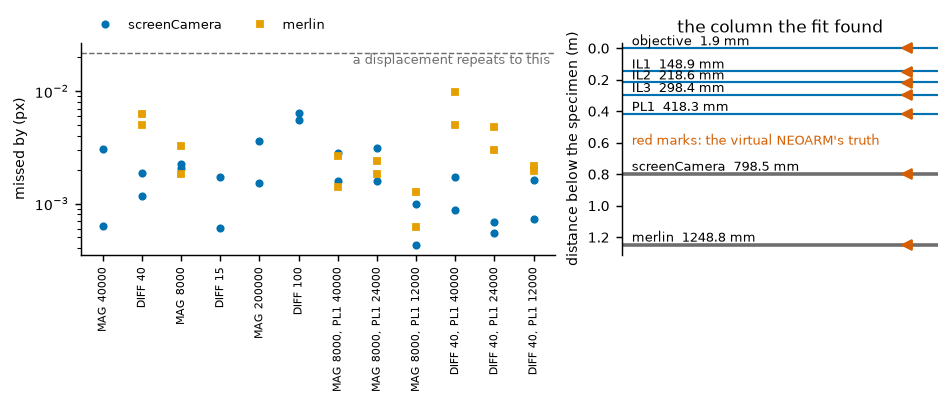

In [9]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130})
BLUE, ORANGE, GREEN, RED, GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#6E6E6E"

figure, (left_panel, right_panel) = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True, width_ratios=[1.5, 1])
for camera, (colour, marker) in enumerate(((BLUE, "o"), (ORANGE, "s"))):
    for kept, face in ((False, colour), (True, "white")):
        chosen = (KICKS["camera"] == camera) & ((KICKS["stage"] == "kept") == kept)
        left_panel.plot(KICKS["setting"][chosen], miss[chosen], marker, ms=3.5, mfc=face, mec=colour, ls="none",
                        label=f"{CAMERAS[camera]}{', kept back' if kept else ''}" if chosen.any() else None)
left_panel.axhline(SCATTER_PX, color=GREY, lw=0.8, ls="--")
left_panel.annotate("a displacement repeats to this", (0.99, SCATTER_PX), xycoords=("axes fraction", "data"), ha="right", va="top", fontsize=7, color=GREY)
left_panel.set_xticks(range(len(settings)), settings, rotation=90, fontsize=6)
left_panel.set(ylabel="missed by (px)", yscale="log")
left_panel.legend(frameon=False, fontsize=7, ncols=3, loc="lower left", bbox_to_anchor=(0, 1.0))

names = ["objective", *LENSES, CAMERAS[0], CAMERAS[1]]
places = [*z, z[5] + separation]
for k, (name, place) in enumerate(zip(names, places)):
    right_panel.axhline(place, color=BLUE if k < 5 else GREY, lw=2 if k >= 5 else 1.2)
    right_panel.annotate(f"{name}  {place * 1e3:.1f} mm", (0.03, place), xycoords=("axes fraction", "data"), va="bottom", fontsize=7)
if truth:
    for place in [*true["z"], true["z"][5] + true["separation"]]:
        right_panel.plot(0.9, place, "<", color=RED, ms=5, transform=right_panel.get_yaxis_transform(), clip_on=False)
    right_panel.annotate("red marks: the virtual NEOARM's truth", (0.03, 0.52), xycoords="axes fraction", fontsize=7, color=RED)
right_panel.set(ylim=(1.05 * places[-1], -0.03), xticks=[], ylabel="distance below the specimen (m)", title="the column the fit found")
right_panel.spines["bottom"].set_visible(False)
plt.show()

**Figure 1.** Left: how far each kick's prediction is from what was recorded (filled: fitted; open: rows that were
kept back). Right: where the fit puts the lenses and the two cameras.

## 9. The model, saved

`results/two_cameras/model.json`: the fitted numbers, in the units above. `column(numbers["lenses"], dac)` rebuilds
the TemGym column for any IL1-PL1 values.

In [10]:
folder = Path("results/two_cameras")
folder.mkdir(parents=True, exist_ok=True)
plain = lambda tree: jax.tree_util.tree_map(lambda v: np.asarray(v).tolist(), tree)
(folder / "model.json").write_text(json.dumps(dict(
    recording=str(RECORDING), simulated=SIMULATED, rulers=HAVE_RULERS, voltage_v=VOLTAGE, pixel_m=PIXEL.tolist(), cameras=CAMERAS,
    repeat_scatter_px=SCATTER_PX, chi2_per_dof=result["chi2"] / result["dof"], numbers=plain(numbers),
    lens_places_m=dict(zip(["objective", *LENSES, CAMERAS[0]], z.tolist())), lens_place_error_m=z_error,
    between_cameras_m=separation, objective_focal_length_m=f_objective, cla1_unit_m=cla1, cla2_unit_rad=cla2,
    lens_centres_m=dict(zip(LENSES, lens_found.tolist())), merlin_middle_m=[float(found[12]), float(found[13])],
    beam_at_specimen=dict(position_m=found[8:10].tolist(), tilt_rad=found[10:12].tolist())), indent=1))
print("saved", folder / "model.json")

saved results/two_cameras/model.json


## What this does not cover

- **The lens law.** The model takes each lens to be a TemGym `ElectromagneticLens` over the values recorded (PL1
  from 12000 to 64000). A real lens may not follow it at both ends (iron saturation at the top). A recording of the
  real microscope shows that as misses that grow along the PL1 steps in Figure 1.
- **How well the lens places are pinned.** Without weak lenses this recording pins them to 5-8 mm, not 1-2 mm.
- **Aberrations.** CLA2 kicks are kept small (1500 units) so that a tilt does not bring in the objective's
  spherical aberration; the model has none.
- **The condenser.** The kicks start at the specimen, so nothing here says where the condenser lenses are; see
  `condenser_design.ipynb`.
- **Error bars are the fit's own.** They do not include anything the model leaves out.